# Hiter začetek: podatkovni paket "Zrak, ki ga dihamo" (ADA Hack 2026)

Zvezek v osmih korakih pokaže, kako naložiti in združiti glavne datoteke paketa. Poti so relativne na mapo `podatki/paket/` (zvezek teče iz `primeri/`). Pri vsakem koraku je zapisano, ali gre za **meritev**, **model** ali **oceno**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
P = Path("..")            # koren paketa (podatki/paket/)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

## 1. Nalaganje in združevanje po `time_utc`

Meritve ARSO (PM10, PM2.5), izpeljana urna inverzija iz meritev ARSO, reanaliza ERA5 (**model**) in CAMS (**model**) za točko Bežigrad. Vse datoteke imajo stolpec `time_utc`, zato je združevanje eno `merge`.

In [2]:
pm = pd.read_csv(P/"01_meritve/arso_lj_pm_urno_2016_2026.csv.gz", parse_dates=["time_utc"], dtype={"pm10_flag": str})
inv = pd.read_csv(P/"03_vreme_inverzija/inverzija_urno_2016_2026.csv", parse_dates=["time_utc"])
era = pd.read_csv(P/"03_vreme_inverzija/era5_openmeteo_urno_2021_2026.csv.gz", parse_dates=["time_utc"],
                  usecols=["time_utc","point_id","temperature_2m","wind_speed_10m","boundary_layer_height"])
era = era[era.point_id == "E403"].drop(columns="point_id")
cams = pd.read_csv(P/"02_modeli/cams_openmeteo_urno_2016_2026.csv.gz", parse_dates=["time_utc"],
                   usecols=["time_utc","point_id","pm10","pm2_5"]).rename(columns={"pm10":"cams_pm10","pm2_5":"cams_pm25"})
cams = cams[cams.point_id == "E403"].drop(columns="point_id")

bez = (pm[pm.station_code == "E403"][["time_utc","pm10","pm25"]]
       .merge(inv, on="time_utc", how="left").merge(era, on="time_utc", how="left").merge(cams, on="time_utc", how="left"))
print(f"Bežigrad: {len(bez):,} ur, {bez.time_utc.min():%Y-%m-%d} – {bez.time_utc.max():%Y-%m-%d}")
bez.tail(3)

Bežigrad: 94,302 ur, 2015-12-31 – 2026-10-31


,time_utc,pm10,pm25,temp_lj_bezigrad,wind_speed_lj_bezigrad,wind_gust_lj_bezigrad,rh_lj_bezigrad,pressure_lj_bezigrad,precip_lj_bezigrad,global_rad_lj_bezigrad,...,dt_bezigrad_topol,inv_topol,dt_bezigrad_kredarica,inv_kredarica,lapse_bezigrad_pasja_ravan_k_per_km,temperature_2m,wind_speed_10m,boundary_layer_height,cams_pm10,cams_pm25
94299,2026-10-31 21:00:00+00:00,14.130,11.348,7.63,1.40,3.0,69.83,987.33,0.0,0.0,...,2.13,0.0,15.17,0.0,-6.06,5.2,0.2,10.0,19.4,17.7
94300,2026-10-31 22:00:00+00:00,12.565,10.565,7.10,0.88,2.4,74.17,987.00,0.0,0.0,...,2.05,0.0,15.10,0.0,-6.11,4.5,1.2,25.0,20.5,18.4
94301,2026-10-31 23:00:00+00:00,14.116,11.478,7.10,0.80,2.0,75.67,987.00,0.0,0.0,...,2.13,0.0,15.15,0.0,-6.25,4.2,1.2,55.0,22.1,18.6


## 2. Zimski dnevni hod PM2.5 po postajah (meritev)

Povprečje po urah dneva za mesece november–februar, vse zime v nizu. Čas je UTC (lokalni zimski čas = UTC + 1).

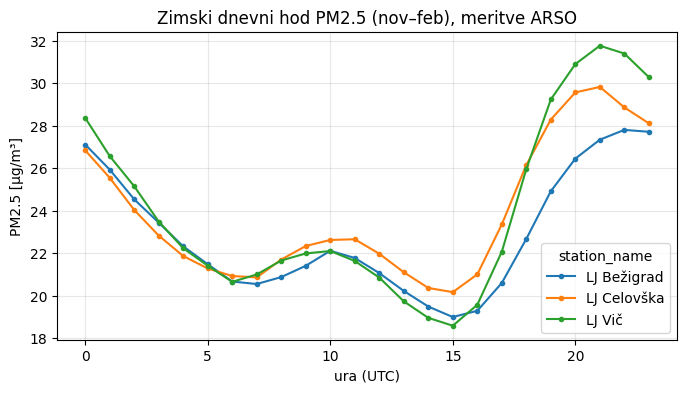

vrh večera (ura UTC, µg/m³):
station_name
LJ Bežigrad    22
LJ Celovška    21
LJ Vič         21 
 station_name
LJ Bežigrad    27.8
LJ Celovška    29.8
LJ Vič         31.8


In [3]:
z = pm[pm.time_utc.dt.month.isin([11,12,1,2])].copy()
z["ura"] = z.time_utc.dt.hour
hod = z.pivot_table(index="ura", columns="station_name", values="pm25", aggfunc="mean")
ax = hod.plot(figsize=(8,4), marker="o", ms=3)
ax.set(xlabel="ura (UTC)", ylabel="PM2.5 [µg/m³]", title="Zimski dnevni hod PM2.5 (nov–feb), meritve ARSO")
ax.grid(alpha=.3); plt.show()
print("vrh večera (ura UTC, µg/m³):"); print(hod.idxmax().to_string(), "\n", hod.max().round(1).to_string())

## 3. Inverzija in višina mejne plasti

Levo: PM2.5 Bežigrad po urah dneva, ko je Pasja ravan (1019 m) toplejša od Bežigrada (inverzija, **meritev**) in ko ni. Desno: PM2.5 proti višini mejne plasti iz ERA5 (**model**), zimske ure.

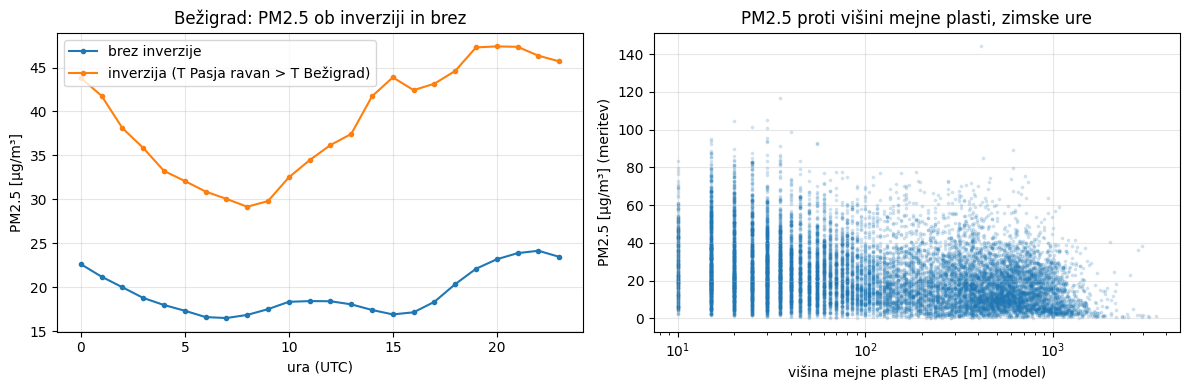

mediana PM2.5 pri mejni plasti < 100 m: 24.2 | pri > 1000 m: 8.0 | delež zimskih ur z inverzijo: 0.19


In [4]:
zb = bez[bez.time_utc.dt.month.isin([11,12,1,2])].copy()
zb["ura"] = zb.time_utc.dt.hour
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12,4))
g = zb.dropna(subset=["inv_pasja_ravan"]).groupby(["ura","inv_pasja_ravan"]).pm25.mean().unstack()
g.columns = ["brez inverzije", "inverzija (T Pasja ravan > T Bežigrad)"]
g.plot(ax=a1, marker="o", ms=3); a1.set(xlabel="ura (UTC)", ylabel="PM2.5 [µg/m³]", title="Bežigrad: PM2.5 ob inverziji in brez"); a1.grid(alpha=.3)
s = zb.dropna(subset=["boundary_layer_height","pm25"])
a2.scatter(s.boundary_layer_height, s.pm25, s=3, alpha=.15)
a2.set(xscale="log", xlabel="višina mejne plasti ERA5 [m] (model)", ylabel="PM2.5 [µg/m³] (meritev)", title="PM2.5 proti višini mejne plasti, zimske ure"); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("mediana PM2.5 pri mejni plasti < 100 m:", round(s[s.boundary_layer_height < 100].pm25.median(),1),
      "| pri > 1000 m:", round(s[s.boundary_layer_height > 1000].pm25.median(),1), "| delež zimskih ur z inverzijo:", round(zb.inv_pasja_ravan.mean(),2))

## 4. CAMS (model) proti ARSO (meritev), zima 2025/26

Tedenska povprečja PM2.5 na Bežigradu. Regionalni model s celico ~10 km sledi poteku le grobo; to zimo je bil na Bežigradu sistematično previsok (druge zime drugače), zato ga uporabljajte kot ozadje in napoved trenda, ne kot vrednost na postaji.

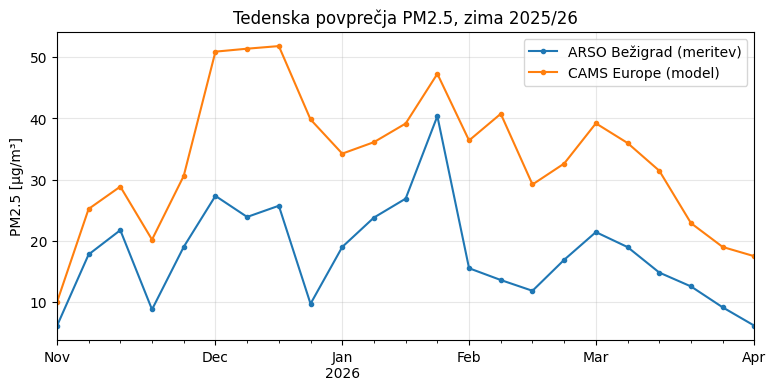

urno: r = 0.44, povprečje ARSO 18.7, CAMS 34.8 µg/m³, ure nad 50 µg/m³: ARSO 105, CAMS 715


In [5]:
w = bez[(bez.time_utc >= "2025-11-01") & (bez.time_utc < "2026-04-01")].set_index("time_utc")[["pm25","cams_pm25"]].resample("W").mean()
ax = w.rename(columns={"pm25":"ARSO Bežigrad (meritev)", "cams_pm25":"CAMS Europe (model)"}).plot(figsize=(9,4), marker="o", ms=3)
ax.set(ylabel="PM2.5 [µg/m³]", xlabel="", title="Tedenska povprečja PM2.5, zima 2025/26"); ax.grid(alpha=.3); plt.show()
h = bez[(bez.time_utc >= "2025-11-01") & (bez.time_utc < "2026-04-01")].dropna(subset=["pm25","cams_pm25"])
print(f"urno: r = {h.pm25.corr(h.cams_pm25):.2f}, povprečje ARSO {h.pm25.mean():.1f}, CAMS {h.cams_pm25.mean():.1f} µg/m³, "
      f"ure nad 50 µg/m³: ARSO {(h.pm25>50).sum()}, CAMS {(h.cams_pm25>50).sum()}")

## 5. Karta: relief, četrtne skupnosti, vročevod, postaje in občanski senzorji

DEM (Copernicus 30 m) kot sivinsko ozadje, ČS MOL, trase vročevoda (ZKGJI, iz EPSG:3794 v WGS84), uradne postaje ARSO in občanski senzorji (Sensor.Community, PurpleAir).

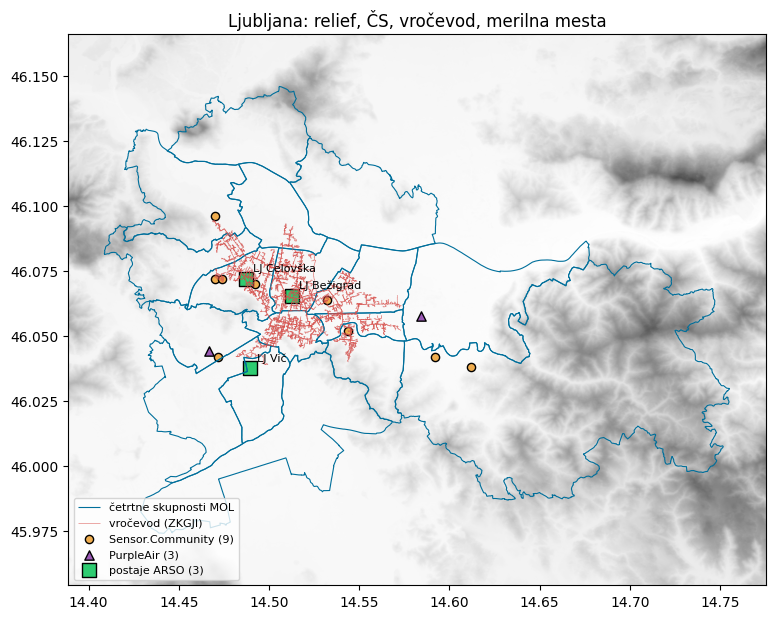

In [6]:
import rasterio
cs = gpd.read_file(P/"04_prostor/mol_cetrtne_skupnosti.geojson")
vro = gpd.read_file(P/"04_prostor/zkgji_vrocevod.gpkg", layer="linije").to_crs(4326)
ars = gpd.read_file(P/"01_meritve/arso_lj_postaje.geojson")
sc = gpd.read_file(P/"01_meritve/sensor_community_lj_naprave.geojson"); sc = sc[~sc["indoor"].astype(bool)]
pa = gpd.read_file(P/"01_meritve/purpleair_lj_naprave.geojson")
with rasterio.open(P/"04_prostor/dem_lj_kotlina_30m.tif") as r:
    dem = r.read(1).astype(float); b = r.bounds
    dem[dem <= 0] = np.nan
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(dem, extent=(b.left, b.right, b.bottom, b.top), cmap="Greys", vmin=250, vmax=900, alpha=.8)
cs.boundary.plot(ax=ax, color="#006f9b", lw=.8, label="četrtne skupnosti MOL")
vro.plot(ax=ax, color="#d9534f", lw=.5, alpha=.7, label="vročevod (ZKGJI)")
sc.plot(ax=ax, color="#f0ad4e", markersize=35, edgecolor="k", label=f"Sensor.Community ({len(sc)})")
pa.plot(ax=ax, color="#9b59b6", markersize=45, marker="^", edgecolor="k", label=f"PurpleAir ({len(pa)})")
ars.plot(ax=ax, color="#2ecc71", markersize=90, marker="s", edgecolor="k", label="postaje ARSO (3)")
for _, r_ in ars.iterrows(): ax.annotate(r_.station_name, (r_.geometry.x, r_.geometry.y), xytext=(5,5), textcoords="offset points", fontsize=8)
xmin, ymin, xmax, ymax = cs.total_bounds
ax.set(xlim=(xmin-.02, xmax+.02), ylim=(ymin-.02, ymax+.02), title="Ljubljana: relief, ČS, vročevod, merilna mesta")
ax.legend(loc="lower left", fontsize=8); plt.show()

## 6. Polje modela CAMx (ARSO, 4,4 km): model

ARSO vsak dan ob 00 UTC požene model CAMx za Slovenijo (celice 4,4 km; vsa MOL je v dveh do treh celicah) in napove urne koncentracije za isti dan (ure +1 … +24, na voljo zjutraj). V paketu je izrez 21 × 21 celic okoli Ljubljane po letih (`02_modeli/camx/camx_kotlina_urno_<leto>.nc`, NetCDF, bere ga `xarray`) in urne vrednosti v celicah postaj (`camx_tocke_urno_2023_2026.csv.gz`). To je **model**, ne meritev: za Bežigrad v zimah 2023/24–2025/26 dnevne vrednosti PM2.5 **precenjuje za okoli 8 µg/m³** (dnevna korelacija 0,64; v zimskih mesecih 2024 spodaj še več) in ima **jutranji vrh ob 6–8 UTC**, ki ga meritve nimajo (meritve imajo vrh ob 22 UTC). Leto 2025 je brez PM2.5, manjka tudi 26. 11. – 31. 12. 2024. Polja v živo niso na voljo; na spletu ARSO so le slike (zajem v `05_zadnji_dnevi/camx/`).

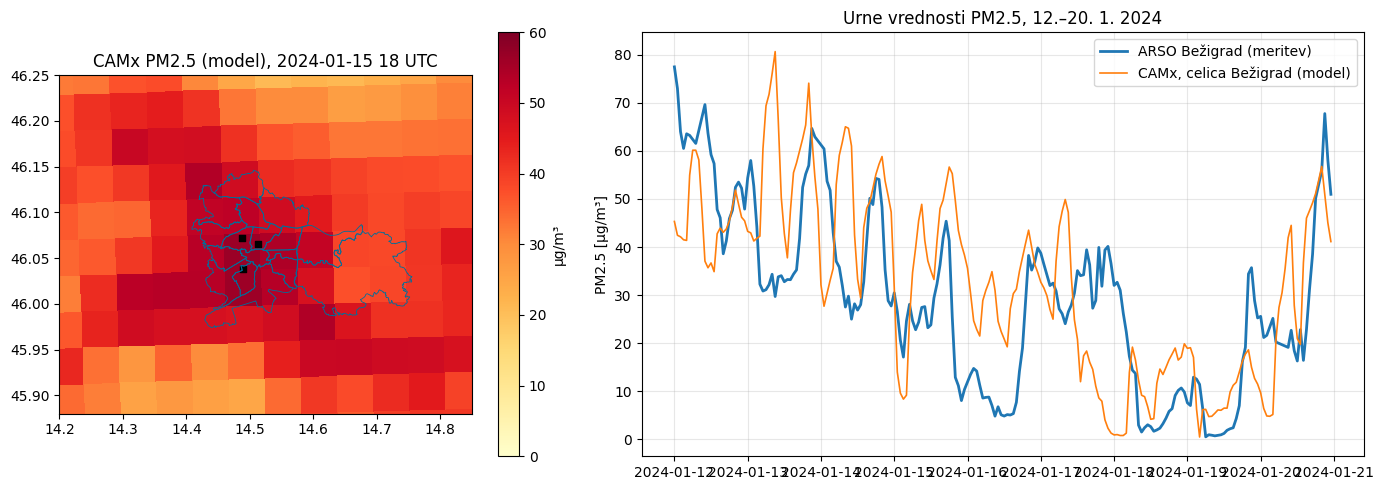

zimski meseci 2024, 83 dni: model 38.0 proti meritvi 25.5 µg/m³ (dnevno povprečje), korelacija dnevno 0.59, urno 0.51
povprečje po urah UTC (model / meritev):
      0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
camx  33  32  31  31  30  43  50  52  50  43  38  32  29  26  32  36  37  38  41  42  45  41  38  35
arso  30  28  26  24  23  22  21  21  21  21  23  23  22  20  19  19  20  22  25  28  30  31  31  30


In [7]:
import xarray as xr
cx = xr.open_dataset(P/"02_modeli/camx/camx_kotlina_urno_2024.nc")
T = "2024-01-15T18:00"                                   # večer z inverzijo, zima 2023/24
iy, ix = int(np.where(cx.row.values == 34)[0][0]), int(np.where(cx.col.values == 55)[0][0])   # celica Bežigrad
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})
mesh = a1.pcolormesh(cx.lon, cx.lat, cx.camx_pm25.sel(time=T), shading="auto", cmap="YlOrRd", vmin=0, vmax=60)
cs.boundary.plot(ax=a1, color="#006f9b", lw=.6)
ars.plot(ax=a1, color="k", markersize=25, marker="s")
a1.set(xlim=(14.2, 14.85), ylim=(45.88, 46.25), title=f"CAMx PM2.5 (model), {T[:10]} 18 UTC")
plt.colorbar(mesh, ax=a1, label="µg/m³")
ser = cx.camx_pm25.isel(y=iy, x=ix).to_series(); ser.index = ser.index.tz_localize("UTC")
b = bez.set_index("time_utc").pm25
w0, w1 = "2024-01-12", "2024-01-20"
a2.plot(b[w0:w1].index, b[w0:w1].values, lw=2, label="ARSO Bežigrad (meritev)")
a2.plot(ser[w0:w1].index, ser[w0:w1].values, lw=1.2, label="CAMx, celica Bežigrad (model)")
a2.set(title="Urne vrednosti PM2.5, 12.–20. 1. 2024", ylabel="PM2.5 [µg/m³]"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()
m = pd.DataFrame({"camx": ser, "arso": b}).dropna(); m = m[m.index.month.isin([1, 2, 11, 12])]
d = m.resample("D").mean().dropna()
print(f"zimski meseci 2024, {len(d)} dni: model {d.camx.mean():.1f} proti meritvi {d.arso.mean():.1f} µg/m³ (dnevno povprečje), "
      f"korelacija dnevno {d.camx.corr(d.arso):.2f}, urno {m.camx.corr(m.arso):.2f}")
print("povprečje po urah UTC (model / meritev):")
print(m.groupby(m.index.hour).mean().round(0).astype(int).T.to_string())

## 7. Umerjanje občanskega senzorja (ocena)

Senzor Sensor.Community 9821 (1,4 km od postaje ARSO Vič): surova vrednost, vrednost po linearnem umerjanju z vlago (iz `senzorji_umerjeno_urno.csv.gz`, **ocena**) in uradna meritev ARSO Vič za najbolj onesnažen teden zime 2025/26.

zima 2025/26, 3620 ur: RMSE surovo 7.2, po umerjanju 6.5 µg/m³; mediana surovo/ARSO 0.87


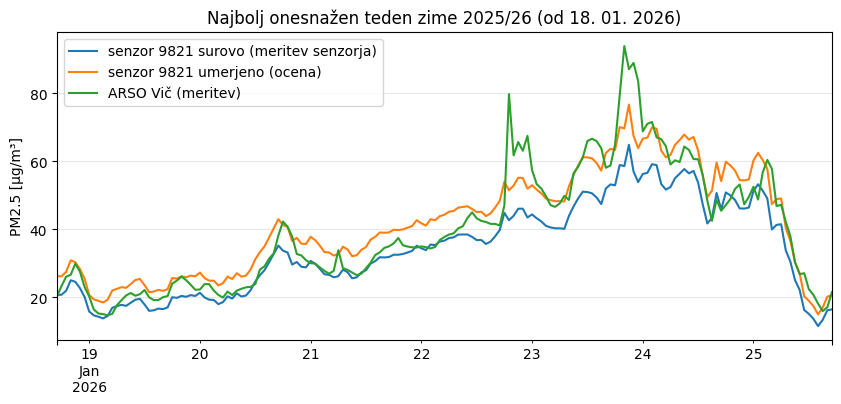

In [8]:
cal = pd.read_csv(P/"01_meritve/senzorji_umerjeno_urno.csv.gz", parse_dates=["time_utc"], dtype={"pm25_cal_note": str, "pm10_cal_note": str})
s = cal[(cal.sensor_id == 9821) & (cal.time_utc >= "2025-11-01") & (cal.time_utc < "2026-04-01")][["time_utc","pm25","pm25_cal"]]
vic = pm[pm.station_code == "E404"][["time_utc","pm25"]].rename(columns={"pm25":"arso_vic"})
m = s.merge(vic, on="time_utc").dropna().set_index("time_utc")
rmse = lambda a, b: np.sqrt(((a-b)**2).mean())
print(f"zima 2025/26, {len(m)} ur: RMSE surovo {rmse(m.pm25, m.arso_vic):.1f}, po umerjanju {rmse(m.pm25_cal, m.arso_vic):.1f} µg/m³; "
      f"mediana surovo/ARSO {(m.pm25/m.arso_vic).median():.2f}")
t0 = m.arso_vic.rolling("7D").mean().idxmax() - pd.Timedelta(days=7)
wk = m[t0:t0 + pd.Timedelta(days=7)]
ax = wk.rename(columns={"pm25":"senzor 9821 surovo (meritev senzorja)", "pm25_cal":"senzor 9821 umerjeno (ocena)", "arso_vic":"ARSO Vič (meritev)"}).plot(figsize=(10,4))
ax.set(ylabel="PM2.5 [µg/m³]", xlabel="", title=f"Najbolj onesnažen teden zime 2025/26 (od {t0:%d. %m. %Y})"); ax.grid(alpha=.3); plt.show()

## 8. Podatki v živo (opcijsko, potrebuje internet)

Skripta `v_zivo/zrak_v_zivo.py` združi zadnjo uro ARSO, zgodovino iz zajema v oblaku in napoved Open-Meteo. Celica se ob napaki (brez interneta) le preskoči.

In [9]:
import sys; sys.path.insert(0, str(P/"v_zivo"))
try:
    from zrak_v_zivo import arso_zadnja_ura, napoved
    z = arso_zadnja_ura(); print(z[z.station_code.isin(["E403","E405","E404"])][["time_local","station_name","pm10","pm25"]].to_string(index=False))
    n = napoved(ure=12); print(n[["time_utc","pm2_5","temperature_2m","boundary_layer_height"]].to_string(index=False))
except Exception as e:
    print("Klic v živo ni uspel (ni interneta ali vir ne odgovarja):", type(e).__name__)

         time_local station_name  pm10  pm25
2026-11-18 14:00:00  LJ Bežigrad   5.0   4.0
2026-11-18 14:00:00  LJ Celovška   6.0   4.0
2026-11-18 14:00:00       LJ Vič  10.0   4.0


                 time_utc  pm2_5  temperature_2m  boundary_layer_height
2026-11-18 15:00:00+00:00   13.8            13.1                  110.0
2026-11-18 16:00:00+00:00   20.6            12.2                   60.0
2026-11-18 17:00:00+00:00   27.9            11.4                   95.0
2026-11-18 18:00:00+00:00   35.2            10.7                  100.0
2026-11-18 19:00:00+00:00   38.6            10.2                   55.0
2026-11-18 20:00:00+00:00   38.6             9.5                   40.0
2026-11-18 21:00:00+00:00   43.4             7.9                   30.0
2026-11-18 22:00:00+00:00   46.1             7.7                   25.0
2026-11-18 23:00:00+00:00   39.7             6.8                   15.0
2026-11-19 00:00:00+00:00   35.5             6.2                   15.0
2026-11-19 01:00:00+00:00   29.1             6.1                   15.0
2026-11-19 02:00:00+00:00   31.3             6.1                   15.0
